In [1]:
import numpy as np
import torch
torch.manual_seed(42)
# embdata=np.load('embdata.npy')
# ydata_norm=np.load('ydata_norm.npy')
np.random.seed(42)
ydata=np.load('ydata.npy')
sampled_point=np.load('sp.npy')
sp3index=np.array([1,5,9])-1
sp3=sampled_point[:,sp3index]

def normalize(x,x_max,x_min):
    # if x_max==x_min:
    #     return np.zeros_like(x)
    return (x-x_min)/(x_max-x_min)*2-1

def denormalize(x,x_max,x_min):
    drange=x_max-x_min
    return (x+1)/2*drange+x_min

sp3max=np.max(sp3,axis=1)
sp3min=np.min(sp3,axis=1)

sp3max_max=sp3max.max()
sp3max_min=sp3max.min()
sp3min_max=sp3min.max()
sp3min_min=sp3min.min()

sp3max_n=normalize(sp3max,sp3max_max,sp3max_min)
sp3min_n=normalize(sp3min,sp3min_max,sp3min_min)

sp3n=normalize(sp3,sp3max.reshape(-1,1),sp3min.reshape(-1,1))

embdata=np.concatenate((sp3n,sp3max_n.reshape(-1,1),sp3min_n.reshape(-1,1)),axis=1)
ydata_norm=normalize(ydata,sp3max.reshape(-1,1,1),sp3min.reshape(-1,1,1))

array=np.arange(0,ydata_norm.shape[0])
index=np.random.choice(array,10000,replace=False)

v_ydata=ydata_norm[index]
v_emb=embdata[index]
t_ydata=np.delete(ydata_norm,index,0)
t_emb=np.delete(embdata,index,0)

from torch.utils.data import Dataset,DataLoader
class MyDataset(Dataset):
    def __init__(self,embdata,ydata):
        self.embdata=embdata
        self.ydata=ydata
    def __len__(self):
        return len(self.embdata)
    def __getitem__(self,idx):
        return self.embdata[idx],self.ydata[idx]

train_dataset=MyDataset(t_emb,t_ydata)
val_dataset=MyDataset(v_emb,v_ydata)
train_loader=DataLoader(train_dataset,batch_size=32)
val_loader=DataLoader(val_dataset,batch_size=50)

In [2]:
import torch
import torch.nn as nn
from tqdm import tqdm
from diffusion_model import DiffusionModel
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# device="cuda:1"

diffusion=DiffusionModel(
    image_size=(40,240),
    channels=1,
    cond_dim=5,
    timesteps=1000,
    device=device
)

diffusion.load('final_model_sp3_0320.pt')

diffusion.model.eval()
y_true=np.empty((0,40,240))
y_pred=np.empty((0,40,240))
x_in=np.empty((0,5))
for veb,vyb in tqdm(val_loader):
    x_in=np.concatenate((x_in,veb.numpy()),axis=0)
    y_true=np.concatenate((y_true,vyb.numpy()),axis=0)
    veb=veb.to(device)
    # vyb=vyb.unsqueeze(1).to(device)
    sample=diffusion.generate(veb, num_samples=vyb.size(0))
    y_pred=np.concatenate((y_pred,sample[:,0,:,:]),axis=0)
    # break

Model loaded from final_model_sp3_0320.pt


100%|██████████| 200/200 [15:58:48<00:00, 287.64s/it]  


In [3]:
i=10
print(y_pred[i])
print(y_true[i])

x_in.shape, y_true.shape, y_pred.shape

[[-1.00149941 -0.99927312 -1.0036763  ... -3.10835385 -3.1240809
  -3.13662291]
 [-0.92630488 -0.92776966 -0.93005371 ... -2.91886735 -2.93262887
  -2.95520806]
 [-0.85676128 -0.85465914 -0.85492224 ... -2.73424506 -2.74606776
  -2.76286101]
 ...
 [ 0.42767861  0.42554432  0.42572099 ...  0.95773202  0.9602263
   0.96382892]
 [ 0.42971489  0.42661828  0.42794016 ...  0.97784156  0.98321038
   0.98351663]
 [ 0.4286778   0.42240068  0.42710754 ...  0.99383283  0.99876177
   1.00569212]]
[[-1.         -1.         -1.         ...  0.40437675  0.41769743
   0.42911518]
 [-0.95432919 -0.95432919 -0.95432919 ...  0.43482399  0.44624162
   0.45765936]
 [-0.90865844 -0.90865844 -0.90675545 ...  0.46146524  0.47288299
   0.48620367]
 ...
 [-0.05042815 -0.05042815 -0.05042815 ...  0.97906756  0.98667932
   0.99619412]
 [-0.04852521 -0.04852521 -0.04662228 ...  0.9809705   0.99048531
   0.99809706]
 [-0.04662228 -0.04662228 -0.04662228 ...  0.98287344  0.99238825
   1.        ]]


((10000, 5), (10000, 40, 240), (10000, 40, 240))

In [4]:
spmax_vector=denormalize(x_in[:,3],sp3max_max,sp3max_min).reshape(-1,1,1)
spmin_vector=denormalize(x_in[:,4],sp3min_max,sp3min_min).reshape(-1,1,1)

true=denormalize(y_true,spmax_vector,spmin_vector)
pred=denormalize(y_pred,spmax_vector,spmin_vector)
spmax_vector.shape,spmin_vector.shape,true.shape, pred.shape

((10000, 1, 1), (10000, 1, 1), (10000, 40, 240), (10000, 40, 240))

In [5]:
def calculate_rmse(matrix1, matrix2):
    error = matrix1 - matrix2    
    # 计算均方误差 (MSE)
    mse = np.mean(error ** 2)    
    # 计算均方根误差 (RMSE)
    rmse = np.sqrt(mse)    
    return rmse
sp3_rmse=[]
for i in range(true.shape[0]):
    rmse=calculate_rmse(true[i],pred[i])
    sp3_rmse.append(rmse)

np.save('sp3_rmse.npy', np.array(sp3_rmse))
np.array(sp3_rmse).shape

(10000,)

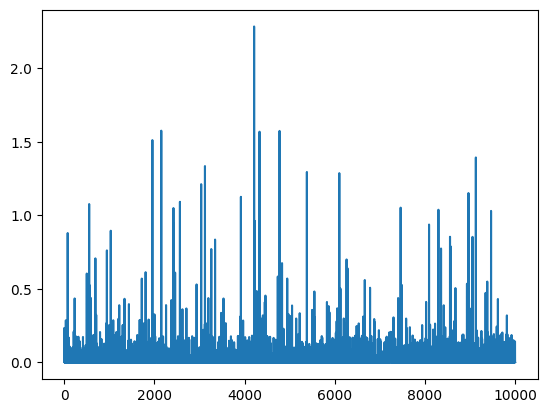

In [6]:
import matplotlib.pyplot as plt
plt.plot(sp3_rmse)

In [7]:
pred[10]

array([[288.77359605, 288.77363175, 288.77356114, ..., 288.73980823,
        288.73955602, 288.73935488],
       [288.77480195, 288.77477846, 288.77474183, ..., 288.74284704,
        288.74262635, 288.74226424],
       [288.77591723, 288.77595094, 288.77594672, ..., 288.74580785,
        288.74561825, 288.74534893],
       ...,
       [288.79651591, 288.79648168, 288.79648451, ..., 288.80501642,
        288.80505642, 288.8051142 ],
       [288.79654856, 288.7964989 , 288.7965201 , ..., 288.80533892,
        288.80542502, 288.80542993],
       [288.79653193, 288.79643126, 288.79650675, ..., 288.80559537,
        288.80567442, 288.80578556]], shape=(40, 240))

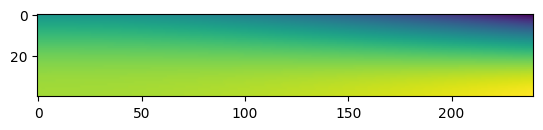

In [8]:
import matplotlib.pyplot as plt
plt.imshow(pred[10], cmap='viridis')

In [9]:
np.mean(sp3_rmse)

np.float64(0.026978637868142256)